Source:  
Manuel Eugenio Morocho Cayamcela, PhD

Autor:
dfreyes

Date:
Octubre 2026

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [ ]:
#%pip install pandas

In [ ]:
#%pip install openpyxl

In [ ]:
#%pip install matplotlib seaborn

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [ ]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.

In [2]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (891, 12)


In [3]:
print("\nData types:\n", df.dtypes)


Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [4]:
print("\nMissing values:\n", df.isnull().sum())


Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [5]:
descriptive_stats = df.describe(include='all')
print("\nDescriptive statistics:\n", descriptive_stats)


Descriptive statistics:
         PassengerId    Survived      Pclass                     Name   Sex  \
count    891.000000  891.000000  891.000000                      891   891   
unique          NaN         NaN         NaN                      891     2   
top             NaN         NaN         NaN  Braund, Mr. Owen Harris  male   
freq            NaN         NaN         NaN                        1   577   
mean     446.000000    0.383838    2.308642                      NaN   NaN   
std      257.353842    0.486592    0.836071                      NaN   NaN   
min        1.000000    0.000000    1.000000                      NaN   NaN   
25%      223.500000    0.000000    2.000000                      NaN   NaN   
50%      446.000000    0.000000    3.000000                      NaN   NaN   
75%      668.500000    1.000000    3.000000                      NaN   NaN   
max      891.000000    1.000000    3.000000                      NaN   NaN   

               Age       SibSp       

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


array([[<Axes: title={'center': 'PassengerId'}>,
        <Axes: title={'center': 'Survived'}>,
        <Axes: title={'center': 'Pclass'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'SibSp'}>,
        <Axes: title={'center': 'Parch'}>],
       [<Axes: title={'center': 'Fare'}>, <Axes: >, <Axes: >]],
      dtype=object)

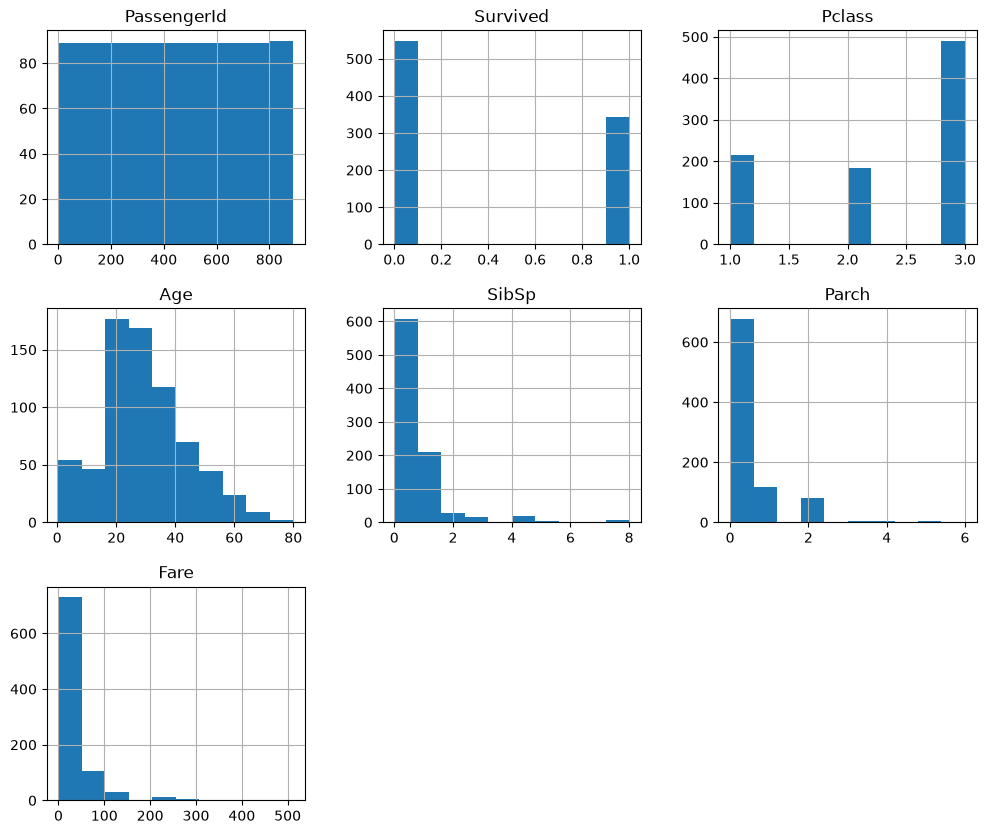

In [7]:
df.hist(figsize=(12, 10))

In [8]:
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005007 -0.035144  0.036847 -0.057527 -0.001652   
Survived       -0.005007  1.000000 -0.338481 -0.077221 -0.035322  0.081629   
Pclass         -0.035144 -0.338481  1.000000 -0.369226  0.083081  0.018443   
Age             0.036847 -0.077221 -0.369226  1.000000 -0.308247 -0.189119   
SibSp          -0.057527 -0.035322  0.083081 -0.308247  1.000000  0.414838   
Parch          -0.001652  0.081629  0.018443 -0.189119  0.414838  1.000000   
Fare            0.012658  0.257307 -0.549500  0.096067  0.159651  0.216225   

                 Fare  
PassengerId  0.012658  
Survived     0.257307  
Pclass      -0.549500  
Age          0.096067  
SibSp        0.159651  
Parch        0.216225  
Fare         1.000000  


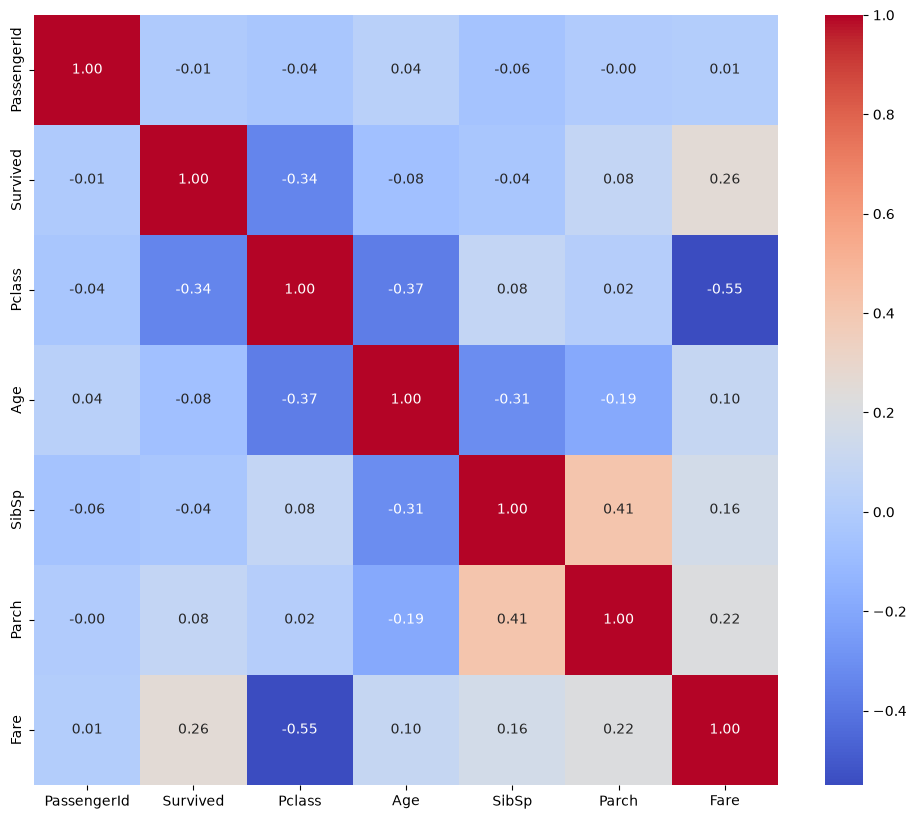

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

Write your answer here..

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

In [10]:
# Calculate survival rates by sex and visualize the comparison.


In [12]:
df_supervivientes = df[df['Survived'] == 1]
total_supervivientes = len(df_supervivientes)

tasas_supervivencia = df.groupby('Sex')['Survived'].mean() * 100
print("Tasas de supervivencia por género:")
print(tasas_supervivencia.map('{:.2f}%'.format))


Tasas de supervivencia por género:
Sex
female    74.20%
male      18.89%
Name: Survived, dtype: str


C:\Users\DiegoR\AppData\Local\Temp\ipykernel_25708\3839638206.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df, x='Sex', y='Survived', palette='Set2', errorbar=None)


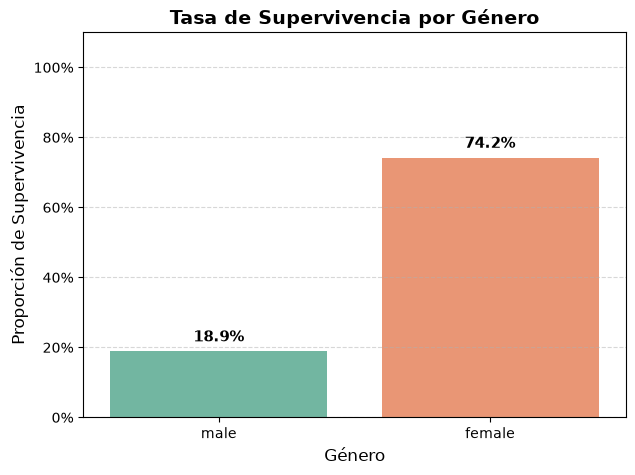

In [14]:

# 2. Configurar el gráfico
plt.figure(figsize=(7, 5))
# Al usar barplot con una variable de 0 y 1, el eje Y muestra la tasa/proporción por defecto
ax = sns.barplot(data=df, x='Sex', y='Survived', palette='Set2', errorbar=None)

# 3. Agregar las etiquetas con el porcentaje exacto sobre las barras
for p in ax.patches:
    tasa = p.get_height() * 100  # Convertir la proporción a porcentaje
    etiqueta = f'{tasa:.1f}%'
    
    ax.annotate(etiqueta, 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points', 
                fontsize=11, fontweight='bold')

# 4. Personalizar el diseño del gráfico
plt.title('Tasa de Supervivencia por Género', fontsize=14, fontweight='bold')
plt.xlabel('Género', fontsize=12)
plt.ylabel('Proporción de Supervivencia', fontsize=12)
plt.ylim(0, 1.1)  # Ajustar el límite para dar espacio a las etiquetas
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0f}%'.format(y*100))) # Formatear eje Y a %
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Mostrar el gráfico
plt.show()


In [20]:
# 1. Creamos la tabla de contingencia básica con cantidades absolutas
tabla = pd.crosstab(
    index=df['Sex'], 
    columns=df['Survived'], 
    margins=True, 
    margins_name='Total General (Cant.)'
)

# Renombramos las columnas para que sea fácil identificar el estado
tabla.columns = ['Fallecidos (Cant.)', 'Vivos (Cant.)', 'Total Pasajeros por Género']

# 2. Obtenemos el gran total del barco (Hombres + Mujeres)
gran_total_pasajeros = tabla.loc['Total General (Cant.)', 'Total Pasajeros por Género']

# 3. Añadimos la columna del Porcentaje respecto al TOTAL GENERAL del barco
# Mide el peso de cada celda sobre el universo completo de pasajeros
tabla['% del Total General (Vivos)'] = (tabla['Vivos (Cant.)'] / gran_total_pasajeros) * 100

# 4. Añadimos la columna de la Tasa de Supervivencia Interna
# Mide el porcentaje de éxito dentro del subgrupo de cada fila
tabla['Tasa de Supervivencia (Interna)'] = (tabla['Vivos (Cant.)'] / tabla['Total Pasajeros por Género']) * 100

# 5. Formateamos estéticamente los porcentajes con el símbolo "%"
columnas_porcentaje = ['% del Total General (Vivos)', 'Tasa de Supervivencia (Interna)']
tabla[columnas_porcentaje] = tabla[columnas_porcentaje].map('{:.2f}%'.format)

# Traducimos las etiquetas de las filas al español
tabla.index = ['Mujeres (female)', 'Hombres (male)', 'TOTAL GENERAL (Barco)']

# 6. Imprimimos el resultado final limpio
tabla

,Fallecidos (Cant.),Vivos (Cant.),Total Pasajeros por Género,% del Total General (Vivos),Tasa de Supervivencia (Interna)
Mujeres (female),81,233,314,26.15%,74.20%
Hombres (male),468,109,577,12.23%,18.89%
TOTAL GENERAL (Barco),549,342,891,38.38%,38.38%


**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

La cantidad de tripulantes fue de 891 personas, de estos 577 son hombres y de este grupo el 12.23% estan vivos, mietras que del gurpo de las 314 son mujeres el 26.15% estan vivas, sin embargo si se analiza como tasa de supervivencia individual agrupado por genero se observa que el 74.20 % tasa supervivencia para mujeres y 18.89% tasa de supervivencia de hombres.  

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

In [ ]:
# Calculate survival rates by passenger class and visualize the comparison.

Estadísticas por Clase:
            mean  sum  count
Pclass                      
1       0.629630  136    216
2       0.472826   87    184
3       0.242363  119    491


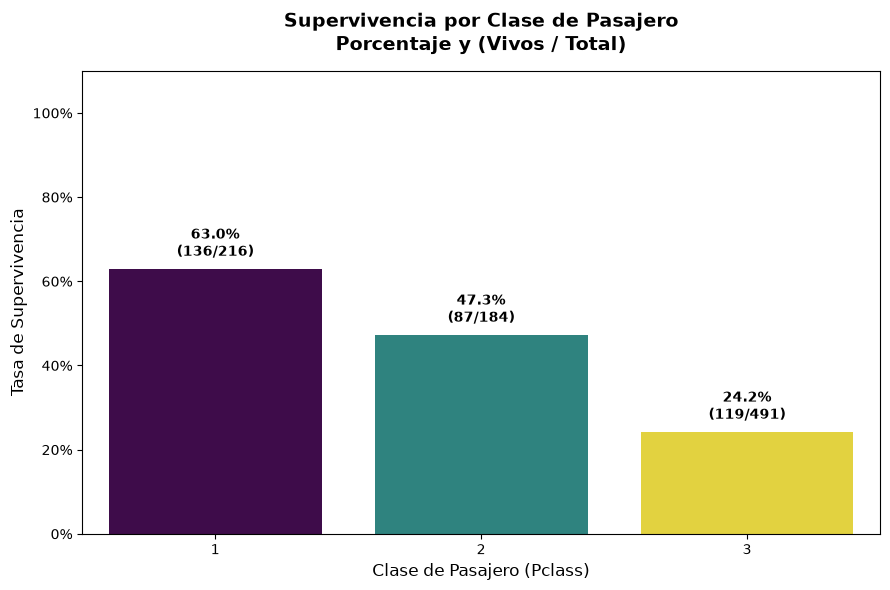

In [26]:
# 1. Calcular métricas: tasa (promedio) y conteos (supervivientes / total)
stats = df.groupby("Pclass")["Survived"].agg(["mean", "sum", "count"])

print("Estadísticas por Clase:")
print(stats)

# 2. Configurar el gráfico con una nueva paleta de color ('viridis')
plt.figure(figsize=(9, 6))
ax = sns.barplot(
    x="Pclass",
    y="Survived",
    data=df,
    errorbar=None,
    palette="viridis",  # Nueva paleta de color
    hue="Pclass",
    legend=False,
)

# 3. Agregar las etiquetas de porcentaje y cantidad sobre cada barra
for p, class_idx in zip(ax.patches, stats.index):
    height = p.get_height()  # Tasa de supervivencia
    total_survived = int(stats.loc[class_idx, "sum"])  # Supervivientes
    total_passengers = int(stats.loc[class_idx, "count"])  # Total pasajeros

    # Texto a mostrar: "Porcentaje% (Supervivientes/Total)"
    label = f"{height*100:.1f}%\n({total_survived}/{total_passengers})"

    # Colocar el texto centrado arriba de cada barra
    ax.text(
        p.get_x() + p.get_width() / 2.0,
        height + 0.02,  # Un pequeño espacio arriba de la barra
        label,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Ajustes estéticos y de formato
plt.title(
    "Supervivencia por Clase de Pasajero\nPorcentaje y (Vivos / Total)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Clase de Pasajero (Pclass)", fontsize=12)
plt.ylabel("Tasa de Supervivencia", fontsize=12)

# Formatear el eje Y a porcentaje y dar margen superior para las etiquetas
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y*100:.0f}%")
)
plt.ylim(0, 1.1)  # Extendemos a 1.1 para que no se corten las etiquetas de arriba

plt.tight_layout()
plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

La cantidad de tripulantes fue de 891 personas, la clase 1 disponde de la mayor tasa d e supervivientes (63%) ya que de 216 personas que forman parte de esta clase  136 lograron sobrevivir. 

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>